# 🔊 Before the Code: How Sound Becomes Numbers (study notes)

> 📝 **Note:** Before starting this project I had **zero background in audio**. I learned the basics in a question-and-answer session with ChatGPT ([my study session, in Indonesian](https://chatgpt.com/share/6ad297f2-11e0-83ec-a39f-1e6e81912bcc)). This cell was then **written by Claude (AI)** at my request, to document what I learned in English, finish the part about the mel scale, and connect everything to the code in this notebook. All the **code** below is typed by me while following the video.
>
> The pictures are computed with real code. Pictures 1 and 7 use a real clip from this dataset (`Mohammed_Aluhaidan/lohaidan_171.wav`). The others use simple made-up waves so the idea is easy to see.

**The goal of this notebook:** listen to a short clip of Quran recitation and guess **which of 12 reciters** is reading.

```
🔊 .wav file  →  🔢 list of numbers  →  🎼 frequencies over time  →  🖼️ mel spectrogram (128 × 256)  →  🧠 CNN  →  12 scores
```

---

## 1. What is sound, and how does it become numbers?

Sound is a **vibration that travels through the air**:

1. Something vibrates (a voice, a string).
2. The air pressure goes **slightly up and down** around its normal level.
3. A **microphone** turns those pressure changes into an electric signal.
4. The computer **measures that signal thousands of times per second** and stores each measurement as **one number**.

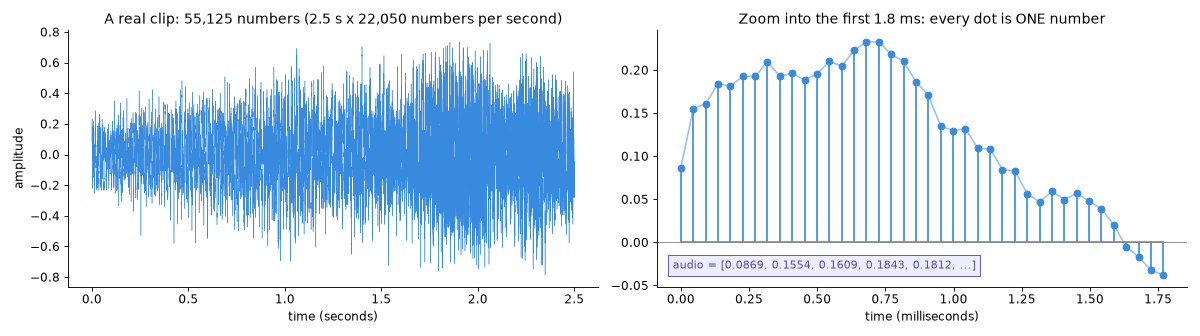

- Each number is the **amplitude** at that moment: how far the signal is from its resting level.
- **Why negative numbers?** `0` is the normal, resting air pressure. **Positive** = pressure a bit higher than normal, **negative** = a bit lower. The sign shows the **direction**, not "less than silence".
- **Is 0 silence?** A long run of zeros is silence. But a single 0 in the middle of a sound is just the wave **passing through the middle**, like a swing passing its lowest point. It's still moving.
- **Sampling rate** = how many numbers per second. The files in this dataset are stored at 48,000 per second, and `librosa.load(..., sr=22050)` turns them into **22,050 numbers per second, in mono**. A 2.5-second clip therefore becomes **2.5 × 22,050 = 55,125 numbers**.

---

## 2. Amplitude vs frequency (two different things!)

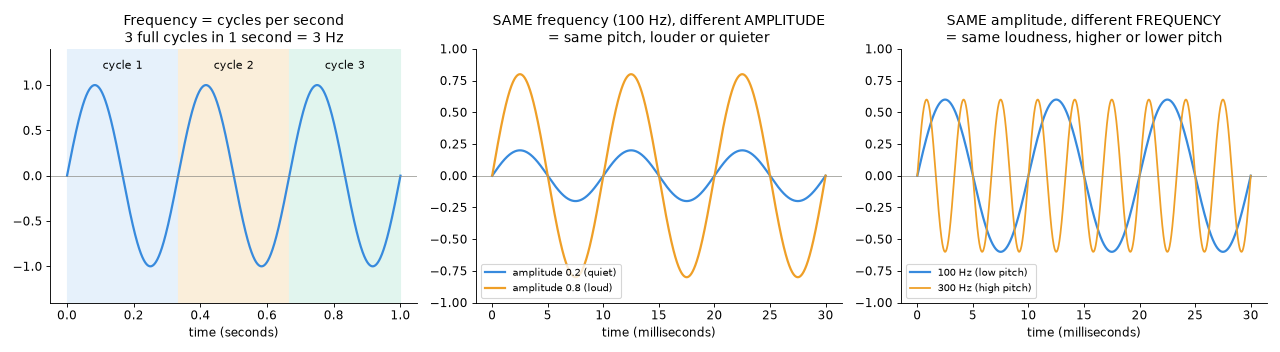

| | What it measures | What we hear |
|---|---|---|
| **Amplitude** | How **big** the vibration is | **Loud or quiet** |
| **Frequency** (Hz) | How **many full cycles per second** | **High or low pitch** |

- **One full cycle** = start in the middle → go up to the top → back down through the middle → down to the bottom → back to the middle. **3 cycles in 1 second = 3 Hz**, and **20 cycles in 2 seconds = 10 Hz**.
- Frequency is **not** how fast someone talks. Someone can hold "aaaa" for 5 seconds in a deep voice (low frequency) or a squeaky voice (high frequency).
- 🎹 **Piano test:** pressing the same key **harder** makes it **louder** (more amplitude), but the **pitch stays the same** (same frequency).
- A real voice is **many frequencies at once** (a main one plus "harmonics"). The mix of these is the **timbre**, the "colour" of a voice. That's why two reciters reading the same verse still sound different, and it's exactly what the model has to learn.

---

## 3. Mixed waves and the Fourier Transform

When two sounds play together, the microphone does **not** record two separate waves. It records **one combined wave**: at every moment, the two values are simply **added**.

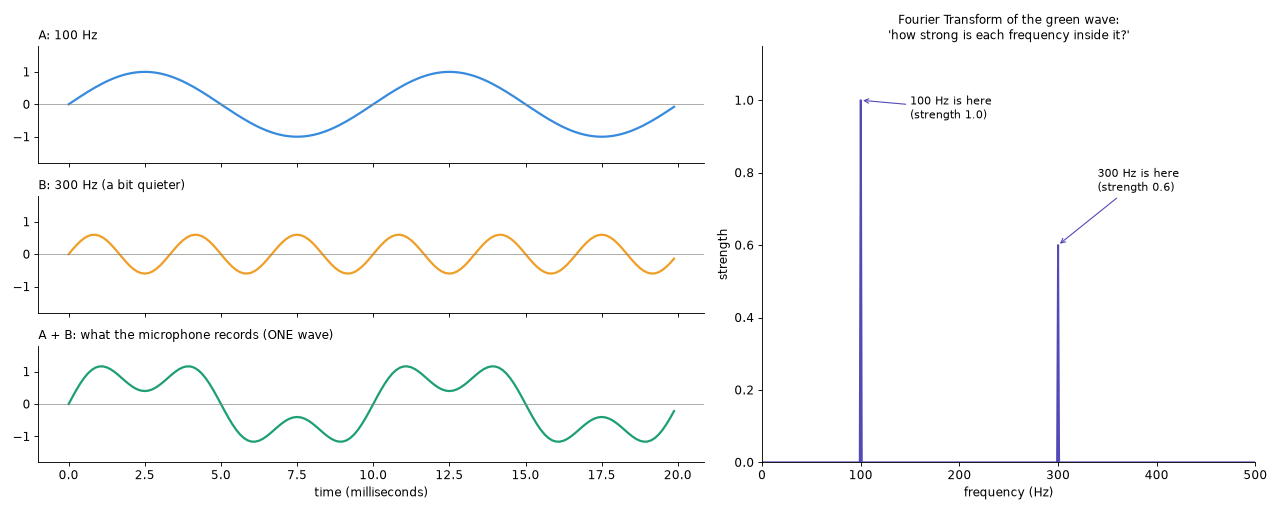

- The green wave looks complicated, but it is **not random**. Its shape is still built from both waves.
- The **Fourier Transform** tests the signal against many pure waves ("is there a 100 Hz pattern in here? a 200 Hz one? a 300 Hz one?") and reports **how strong each frequency is**.
- On the right, it finds exactly two peaks: **100 Hz** (strength 1.0) and **300 Hz** (strength 0.6). It does **not** give back two audio files. It gives a **list of frequency strengths**.

---

## 4. When pitch changes over time: the STFT → spectrogram

A reciter's voice goes up and down. A Fourier Transform over the **whole** clip says *which* frequencies appear, but not **when**. The **Short-Time Fourier Transform (STFT)** fixes that:

1. Cut the sound into **short, overlapping windows**.
2. Run a Fourier Transform on **each window**.
3. Put the results **side by side**.

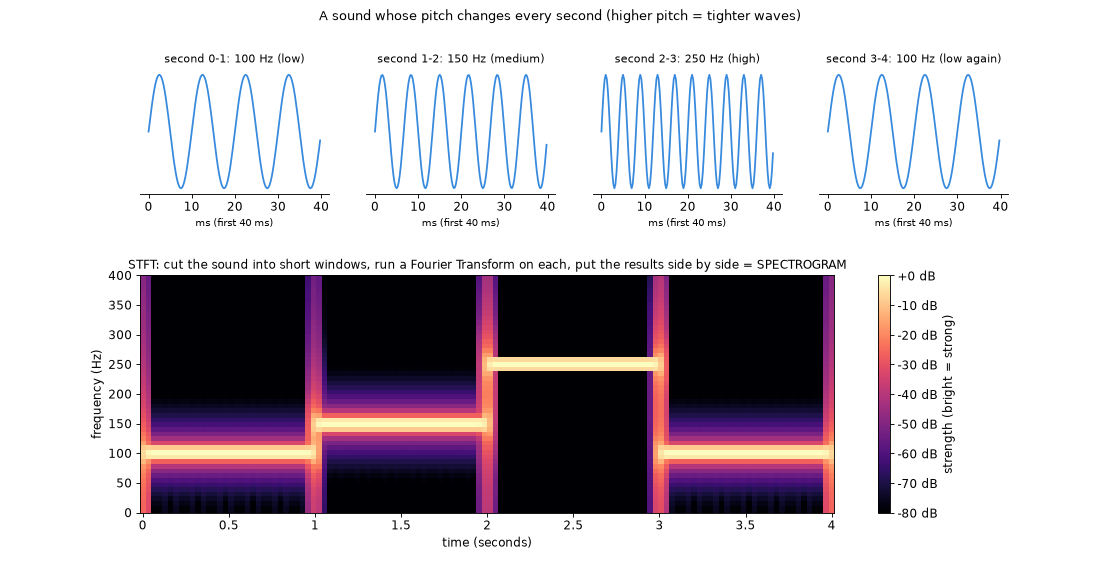

The result is a **spectrogram**: **time** goes left to right, **frequency** goes bottom to top, and **brightness = strength**. You can literally see the pitch step up (100 → 150 → 250 Hz) and come back down.

In this notebook, each window is `n_fft = 2048` numbers (**93 ms**), and the window moves forward `hop_length = 512` numbers (**23 ms**) each time.

### A spectrogram is just a table of numbers

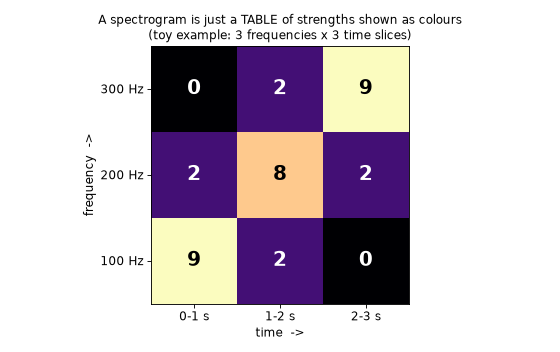

Each box holds **one number: how strong that frequency is at that moment**. Colours only make the table easier to read. For example, the bright box at **300 Hz, 2–3 s** means "a strong 300 Hz component during seconds 2 to 3". It is **not** an amplitude of 300. And because it's a 2D table, a **CNN can read it just like an image**.

---

## 5. Why "mel"? Because ears are not rulers

This is where my ChatGPT session stopped, with this question: *is going from 100 → 200 Hz the same "size" of change as going from 5,000 → 5,100 Hz?* Both are +100 Hz, but **to our ears, no**:

- **100 → 200 Hz** sounds like a **big** jump (the pitch doubles, a full octave).
- **5,000 → 5,100 Hz** sounds like a **tiny** change.

The **mel scale** is a way of measuring pitch **the way humans hear it**:

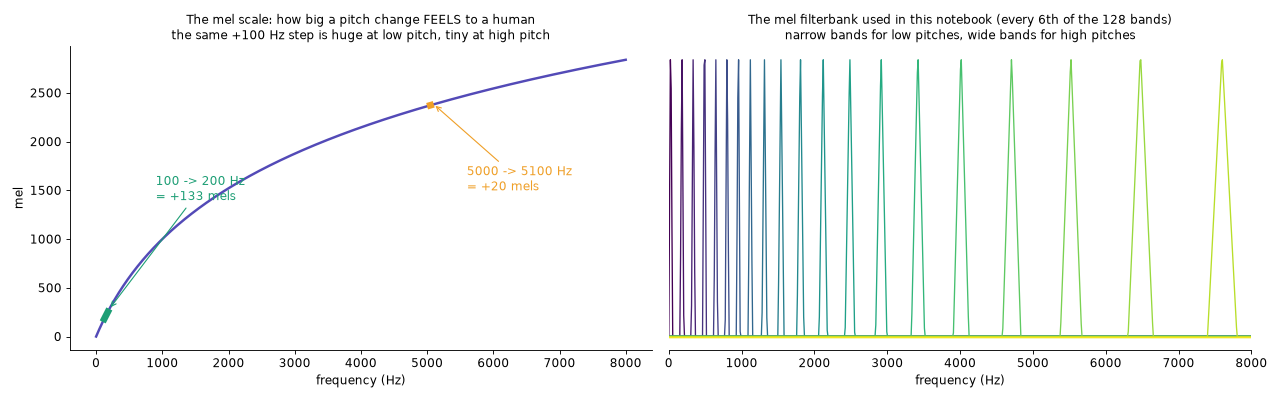

- **Left:** with the classic mel formula, 100 → 200 Hz = **+133 mels**, but 5,000 → 5,100 Hz = only **+20 mels**.
- **Right:** a **mel filterbank** groups the many STFT frequencies into **128 bands** (`n_mels=128`). Low bands are **narrow** (about 26 Hz wide near 200 Hz), high bands are **wide** (about 131 Hz wide near 5,000 Hz). So the picture keeps **more detail at low pitches**, where voices carry most of their character, and squeezes the high pitches.
- librosa uses a slightly different version of the mel formula by default (the "Slaney" version), but the idea is the same.

Then `librosa.power_to_db(..., ref=np.max)` turns strength into **decibels (dB)**, which is also closer to how we hear loudness. The loudest point becomes **0 dB**, and quieter parts become negative, down to **−80 dB**.

---

## 6. What this notebook's code actually does (one real clip)

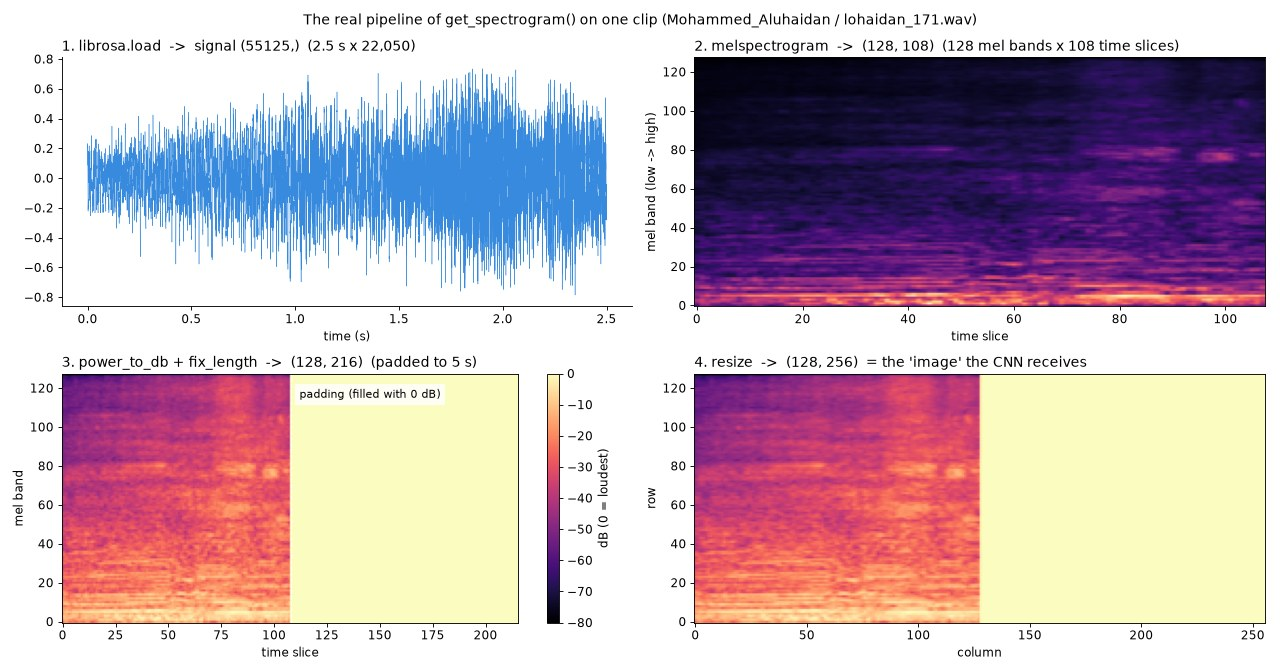

| Line in `get_spectrogram()` | What happens | Shape |
|---|---|---|
| `librosa.load(file_path, sr=22050, duration=5)` | read up to 5 s, as 22,050 numbers per second, mono | `(55125,)` for a 2.5 s clip |
| `librosa.feature.melspectrogram(..., n_fft=2048, hop_length=512, n_mels=128)` | STFT + mel filterbank | `(128, 108)` = 128 mel bands × 108 time slices |
| `librosa.power_to_db(spec, ref=np.max)` | strength → decibels (0 dB = loudest) | `(128, 108)` |
| `librosa.util.fix_length(spec_db, size=...)` | make every clip **5 s long** | `(128, 216)` |
| `resize(..., (128, 256))` | stretch to one fixed image size | `(128, 256)` |
| `.unsqueeze(0)` in `__getitem__` | add the "1 channel" dimension | `(1, 128, 256)` |

Then the CNN treats this `(1, 128, 256)` "image" exactly like Project 02 treated photos, and outputs **12 scores**, one per reciter.

### ⚠️ Worth knowing: the bright block on the right
- **5,419** clips are **2.5 s** long, **1,266** are **5 s** long (and 2 are 4.9 s).
- `fix_length` fills the missing time with the number **0**. In dB, 0 means **the loudest value**, so the empty half becomes a **flat bright block** (step 3 above).
- The share of 5-second clips is **different for each reciter**. Some reciters have none at all, while Saud Alshuraim has 240. So the model might partly learn *"is there a bright block?"* instead of only *"what does this voice sound like?"*. For this notebook I'm following the video. It's just good to be aware of it.

---

## 7. Mini dictionary

| Term | Simple meaning |
|---|---|
| **Amplitude** | How big the vibration is → loudness |
| **Frequency (Hz)** | Full cycles per second → pitch |
| **Sampling rate** | How many numbers are recorded per second |
| **Waveform** | The raw list of amplitude numbers over time |
| **Timbre** | The "colour" of a voice, from its mix of frequencies |
| **Fourier Transform** | Finds how strong each frequency is inside a signal |
| **STFT** | Fourier Transform on many short windows → frequencies **over time** |
| **Spectrogram** | A table (time × frequency) of strengths, shown as colours |
| **Mel scale** | A pitch scale that matches human hearing |
| **Mel spectrogram** | A spectrogram whose frequency rows are grouped into mel bands |
| **Decibel (dB)** | A loudness scale that matches human hearing (here, 0 dB = loudest) |

## References
- My study session with ChatGPT, in Indonesian: [chatgpt.com/share/6ad297f2-11e0-83ec-a39f-1e6e81912bcc](https://chatgpt.com/share/6ad297f2-11e0-83ec-a39f-1e6e81912bcc)
- Omar M. Atef, [PyTorch Tutorial 4 – Audio Classification](https://www.youtube.com/watch?v=uj6s5uhwDkY) and the original notebook [Ex_4_Audio_Classification.ipynb](https://github.com/omaratef3221/pytorch_tutorials/blob/main/Ex_4_Audio_Classification.ipynb)
- Dataset: [Quran recitations for audio classification](https://www.kaggle.com/datasets/mohammedalrajeh/quran-recitations-for-audio-classification) by mohammedalrajeh on Kaggle
- 3Blue1Brown, [But what is the Fourier Transform? A visual introduction](https://www.youtube.com/watch?v=spUNpyF58BY)
- Wikipedia: [Mel scale](https://en.wikipedia.org/wiki/Mel_scale) and [Short-time Fourier transform](https://en.wikipedia.org/wiki/Short-time_Fourier_transform)
- librosa docs: [`stft`](https://librosa.org/doc/latest/api/generated/librosa.stft.html), [`feature.melspectrogram`](https://librosa.org/doc/latest/api/generated/librosa.feature.melspectrogram.html), [`power_to_db`](https://librosa.org/doc/latest/api/generated/librosa.power_to_db.html)

## Imports

In [1]:
import torch # Main PyTorch library
from torch import nn # Neural network module (Used for creating layers and Loss functions)
from torch.optim import Adam # Optimizer (Used for updating weights)
from torch.utils.data import DataLoader, Dataset # Dataset(Used for creating datasets) and DataLoader (Used for batching and shuffling data)

import librosa # Audio processing library (Used for loading and processing audio files)

from sklearn.preprocessing import LabelEncoder # Label encoder (Used for encoding categorical labels into numerical values)
import matplotlib.pyplot as plt # Plotting library (Used for visualizing data and results)
import pandas as pd # Data manipulation library (Used for handling tabular data and CSV files)
import numpy as np # Numerical computing library (Used for array operations and mathematical functions)
import os # Operating system library (Used for file and directory operations)
import time # Used to calculate time for each epoch or any processing time in seconds
from skimage.transform import resize # Used for resizing images (Used for resizing spectrograms)


In [2]:
# Detect if GPU is available and set the device accordingly
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Data

In [3]:
data_df = pd.read_csv("../data/quran-recitations-for-audio-classification/files_paths.csv")
data_df.head()

,FilePath,Class
0,./Dataset/Mohammed_Aluhaidan/lohaidan_171.wav,Mohammed_Aluhaidan
1,./Dataset/Mohammed_Aluhaidan/lohaidan_159.wav,Mohammed_Aluhaidan
2,./Dataset/Mohammed_Aluhaidan/lohaidan_401.wav,Mohammed_Aluhaidan
3,./Dataset/Mohammed_Aluhaidan/lohaidan_367.wav,Mohammed_Aluhaidan
4,./Dataset/Mohammed_Aluhaidan/lohaidan_373.wav,Mohammed_Aluhaidan


In [4]:
data_df['FilePath'] = '../data/quran-recitations-for-audio-classification/Dataset/' + data_df['FilePath'].str[2:]  # Remove the leading './' from the file paths
data_df.head()

,FilePath,Class
0,../data/quran-recitations-for-audio-classifica...,Mohammed_Aluhaidan
1,../data/quran-recitations-for-audio-classifica...,Mohammed_Aluhaidan
2,../data/quran-recitations-for-audio-classifica...,Mohammed_Aluhaidan
3,../data/quran-recitations-for-audio-classifica...,Mohammed_Aluhaidan
4,../data/quran-recitations-for-audio-classifica...,Mohammed_Aluhaidan


## Data Investigation

Data Shape is: (6687, 2)

Class Distribution:


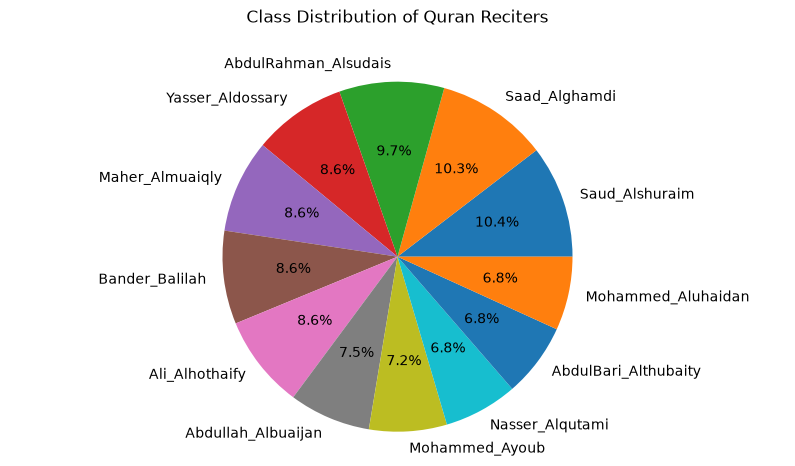

In [5]:
print("Data Shape is:", data_df.shape)
print()
print("Class Distribution:")

class_distribution = data_df['Class'].value_counts()
plt.figure(figsize=(10, 5))
plt.pie(class_distribution, labels=class_distribution.index, autopct='%1.1f%%') # autopct='%1.1f%%' shows the percentage of each slice with one decimal place
plt.title("Class Distribution of Quran Reciters", pad=30) # give a margin between the title and the pie chart for better visualization
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show() # visualize the class distribution of Quran reciters in the dataset using a pie chart.

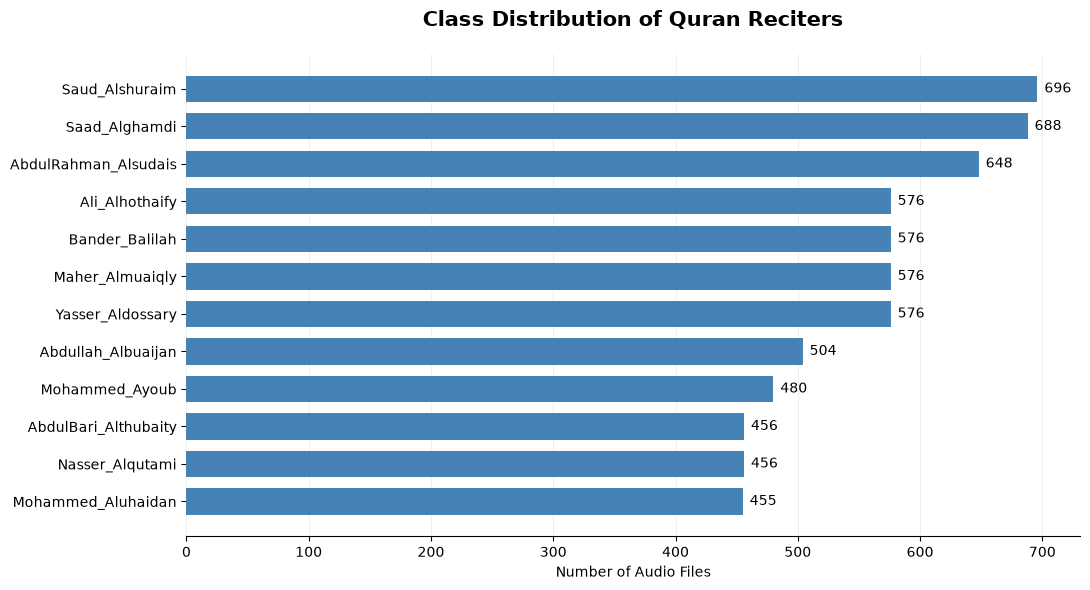

In [6]:
class_distribution = data_df["Class"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    class_distribution.index,
    class_distribution.values,
    color="steelblue",
    height=0.7
)

ax.bar_label(bars, padding=5)

ax.set_title(
    "Class Distribution of Quran Reciters",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Number of Audio Files")
ax.set_ylabel("")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Data Split 

- Training: 70%
- Validation: 15%
- Testing: 15%

In [7]:
label_encoder = LabelEncoder()
data_df["Class"] = label_encoder.fit_transform(data_df["Class"]) # Encode the categorical labels into numerical values using LabelEncoder from sklearn.preprocessing. The fit_transform method is used to fit the encoder to the unique classes in the "Class" column and transform them into numerical values. The transformed values are then assigned back to the "Class" column in the data_df DataFrame.

for index, name in enumerate(label_encoder.classes_):
    print(index, name)

0 AbdulBari_Althubaity
1 AbdulRahman_Alsudais
2 Abdullah_Albuaijan
3 Ali_Alhothaify
4 Bander_Balilah
5 Maher_Almuaiqly
6 Mohammed_Aluhaidan
7 Mohammed_Ayoub
8 Nasser_Alqutami
9 Saad_Alghamdi
10 Saud_Alshuraim
11 Yasser_Aldossary


In [8]:
train = data_df.sample(frac=0.7, random_state=42) # Randomly sample 70% of the data for training
test = data_df.drop(train.index) # Use the remaining 30% of the data for testing

val = test.sample(frac=0.5, random_state=42) # Randomly sample 50% of the test data for validation
test = test.drop(val.index) # Use the remaining 50% of the test data for testing

print("Training shape:", train.shape) # 70% of the data is used for training, so the shape of the training set is printed.
print("Validation shape:", val.shape) # 15% of the data is used for validation, so the shape of the validation set is printed.
print("Testing shape:", test.shape) # 15% of the data is used for testing, so the shape of the testing set is printed.

Training shape: (4681, 2)
Validation shape: (1003, 2)
Testing shape: (1003, 2)


## Custom Dataset Class

In [9]:
class CustomAudioDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe # Store the input dataframe as an instance variable for later use in the dataset.
        self.labels = torch.tensor(list(dataframe["Class"].values), dtype=torch.long).to(device) # Convert the "Class" column of the dataframe to a PyTorch tensor of type long and move it to the specified device (CPU or GPU) for efficient computation during training.
        self.audios = [torch.tensor(self.get_spectrogram(path)).type(torch.float32) for path in dataframe["FilePath"]] #  Store for each audio file path in the "FilePath" column of the dataframe, compute its spectrogram using the get_spectrogram method, convert it to a PyTorch tensor of type float32, and store it in a list for later use in the dataset.

    def __len__(self):
        return self.dataframe.shape[0] # Return the number of samples in the dataset, which is equal to the number of rows in the input dataframe.

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx, 0] # Get the file path of the audio file at the specified index (idx) from the dataframe.
        label = self.labels[idx] # Get the label (already on the device from __init__).
        audio = (self.audios[idx]).unsqueeze(0).to(device) # Get the corresponding audio spectrogram for the audio file at the specified index (idx), add an extra dimension to represent the channel (unsqueeze(0)), and move it to the specified device (CPU or GPU).
        return audio, label

    def get_spectrogram(self, file_path):
        sr = 22050 # Sample rate for audio files
        duration = 5 # Duration of audio files in seconds

        # Set the size of the spectrogram images
        img_height = 128
        img_width = 256

        # Load the audio file using librosa
        signal, sr = librosa.load(file_path, sr=sr, duration=duration)

        # Compute the spectrogram
        spec = librosa.feature.melspectrogram(y=signal, sr=sr, n_fft=2048, hop_length=512, n_mels=128) # Compute the Mel-scaled spectrogram of the audio signal using librosa's melspectrogram function. The parameters specify the audio signal, sample rate, FFT window size, hop length, and number of Mel bands.

        # Convert the spectrogram to decibel scale
        spec_db = librosa.power_to_db(spec, ref=np.max) # Convert the power spectrogram to decibel (dB) scale using librosa's power_to_db function. The ref parameter specifies the reference value for the conversion, which is set to the maximum value of the spectrogram.

        # Resize the spectrogram to the desired size
        spec_resized = librosa.util.fix_length(spec_db, size=duration * sr // 512 + 1) # Resize the spectrogram to a fixed length using librosa's fix_length function. The size parameter is calculated based on the desired duration of the audio files and the hop length used in the spectrogram computation.
        # Aliasing is a phenomenon that occurs when high-frequency components of a signal are undersampled, leading to distortion and artifacts in the reconstructed signal. In the context of resizing images, anti-aliasing techniques are used to reduce these artifacts and produce smoother and more visually appealing results. By applying anti-aliasing during the resizing process, we can minimize the loss of information and maintain the quality of the spectrogram images, which is important for training deep learning models effectively.
        spec_resized = resize(spec_resized, (img_height, img_width), anti_aliasing=True) # Resize the spectrogram to the specified image height and width using skimage's resize function. The anti_aliasing parameter is set to True to reduce aliasing artifacts during resizing.
        return spec_resized

## Create Dataset Objects

In [10]:
train_dataset = CustomAudioDataset(dataframe=train) # Create an instance of the CustomAudioDataset class for the training set using the train dataframe.
val_dataset = CustomAudioDataset(dataframe=val) # Create an instance of the CustomAudioDataset class for the validation set using the val dataframe.
test_dataset = CustomAudioDataset(dataframe=test) # Create an instance of the CustomAudioDataset class for the testing set using the test dataframe.

D:\Workspace\PyTorch_5_Projects_Learning_2026\pytorch-5-projects-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Hyperparameters

In [11]:
LR = 1e-4 # equal to 0.0001, which is a common starting point for learning rates in deep learning models. It controls the step size at each iteration while moving toward a minimum of the loss function. A smaller learning rate can lead to more stable convergence but may require more epochs to train, while a larger learning rate can speed up training but may risk overshooting the optimal solution.
BATCH_SIZE = 16 # Batch size for training, validation, and testing. It determines the number of samples that will be propagated through the network at once. A smaller batch size can lead to more noisy gradient estimates but may help in generalization, while a larger batch size can provide more stable gradient estimates but may require more memory and computational resources.
EPOCHS = 25 # The number of complete passes through the entire training dataset during the training process. Each epoch consists of multiple iterations, where the model's weights are updated based on the computed gradients from the loss function. A higher number of epochs can lead to better learning and convergence, but it may also increase the risk of overfitting if the model is trained for too long without proper regularization or early stopping mechanisms.

## Data Loaders

In [12]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True) # Create a DataLoader for the training dataset with the specified batch size and shuffling enabled to randomize the order of samples during training.
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False) # Create a DataLoader for the validation dataset with the specified batch size and shuffling disabled to maintain the order of samples during validation.
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False) # Create a DataLoader for the testing dataset with the specified batch size and shuffling disabled to maintain the order of samples during testing.

## Model

This code defines a neural network class named `Net`, which inherits from the class `nn.Module` in PyTorch.

- `__init__(self)`: this is where the neural network is set up. Each layer of the network is defined here.
  - `self.conv1`, `self.conv2`, `self.conv3`: convolutional layers. They are particularly good at processing data that has a grid-like shape, like images (or in this case, spectrograms from audio data). They work by sliding a small window over the input and transforming the section of data inside this window at each step.
  - `self.pooling`: a pooling layer, which reduces the size of its input, helping the network focus on the most important information.
  - `self.relu`: an activation function that adds non-linearity to the network (helping it learn complex patterns).
  - `self.flatten`: flattens the output of the previous layers into a one-dimensional array, which can then be fed into traditional dense (fully connected) layers.
  - `self.linear1`, `self.linear2`, `self.linear3`: dense layers, where each neuron is connected to all neurons in the previous layer. They are good at learning complex relationships in data.
  - `self.output`: the final layer that outputs the predictions. The number of neurons here is equal to the number of unique classes in the data (12 reciters).
  - `self.dropout`: a dropout layer, used to prevent overfitting (when the model learns the training data too well and performs poorly on new, unseen data).

  How do we know the input size of the first linear layer? From `get_spectrogram` in `CustomAudioDataset`, the input height is 128 and the width is 256, with only 1 channel. Each pooling layer halves the height and the width:

  - Start: `(1, 128, 256)`
  - After `conv1`: `(16, 128, 256)`
  - After the first pooling: `(16, 64, 128)`
  - After `conv2`: `(32, 64, 128)`
  - After the second pooling: `(32, 32, 64)`
  - After `conv3`: `(64, 32, 64)`
  - After the third pooling: `(64, 16, 32)`

  So the input size of the first linear layer is `64 × 16 × 32 = 32,768`.

- `forward(self, x)`: defines how the data flows through the network, from input to output. The data `x` passes through each layer in the order written here. After each convolution and pooling layer, the shape of the data changes, and at the end the network returns its final output (12 scores).

In [13]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size = 3, padding = 1) # Define the first convolutional layer with 1 input channel (grayscale image), 16 output channels (feature maps), a kernel size of 3x3, and padding of 1 to maintain the spatial dimensions of the input.
        self.conv2 = nn.Conv2d(16, 32, kernel_size = 3, stride = 1, padding = 1) # Define the second convolutional layer with 16 input channels (from the previous layer), 32 output channels (feature maps), a kernel size of 3x3, stride of 1, and padding of 1 to maintain the spatial dimensions of the input.
        self.conv3 = nn.Conv2d(32, 64, kernel_size = 3, stride = 1, padding = 1) # Define the third convolutional layer with 32 input channels (from the previous layer), 64 output channels (feature maps), a kernel size of 3x3, stride of 1, and padding of 1 to maintain the spatial dimensions of the input.
        self.pooling = nn.MaxPool2d(2, 2) # Define the max pooling layer with a kernel size of 2x2 and a stride of 2.
        self.relu = nn.ReLU() # Define the ReLU activation function to introduce non-linearity after each convolutional layer.

        self.flatten = nn.Flatten() # Define a flattening layer to convert the 2D feature maps into a 1D vector for the fully connected layers.
        self.linear1 = nn.Linear((64 * 16 * 32), 4096) # Define the first fully connected layer with input size equal to the flattened feature maps (64 channels * 16 height * 32 width) and output size of 4096 neurons.
        self.linear2 = nn.Linear(4096, 1024) # Define the second fully connected layer with input size of 4096 neurons and output size of 1024 neurons.
        self.linear3 = nn.Linear(1024, 512) # Define the third fully connected layer with input size of 1024 neurons and output size of 512 neurons.
        self.output = nn.Linear(512, len(data_df["Class"].unique())) # Define the output layer with input size of 512 neurons and output size equal to the number of unique classes in the dataset (number of reciters).

        self.dropout = nn.Dropout(0.5) # Define a dropout layer with a dropout probability of 0.5 to prevent overfitting by randomly setting half of the input units to zero during training.

    def forward(self, x):
        x = self.conv1(x) # -> Outputs: (16, (128, 256))
        x = self.pooling(x) # -> Outputs: (16, (64, 128))
        x = self.relu(x)
        x = self.dropout(x)
        x = self.conv2(x) # -> Outputs: (32, (64, 128))
        x = self.pooling(x) # -> Outputs: (32, (32, 64))
        x = self.relu(x)
        x = self.dropout(x)
        x = self.conv3(x) # -> Outputs: (64, (32, 64))
        x = self.pooling(x) # -> Outputs: (64, (16, 32))
        x = self.relu(x)
        x = self.dropout(x)
        x = x.view(x.size(0), -1)

        x = self.flatten(x)

        x = self.linear1(x)
        x = self.dropout(x)

        x = self.linear2(x)
        x = self.dropout(x)

        x = self.linear3(x)
        x = self.dropout(x)

        x = self.output(x)

        return x

model = Net().to(device) # Create an instance of the Net class and move it to the specified device (CPU or GPU) for training and inference.

print(model) # Print the architecture of the model to visualize the layers and their configurations.

Net(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pooling): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=32768, out_features=4096, bias=True)
  (linear2): Linear(in_features=4096, out_features=1024, bias=True)
  (linear3): Linear(in_features=1024, out_features=512, bias=True)
  (output): Linear(in_features=512, out_features=12, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


## Model Summary

In [14]:
from torchsummary import summary # Visualize the model layers and number of parameters
summary(model, (1, 128, 256)) # Visualize the model layers by taking the input size expected (-1 in the output will be replaced by the batch size in training)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 128, 256]             160
         MaxPool2d-2          [-1, 16, 64, 128]               0
              ReLU-3          [-1, 16, 64, 128]               0
           Dropout-4          [-1, 16, 64, 128]               0
            Conv2d-5          [-1, 32, 64, 128]           4,640
         MaxPool2d-6           [-1, 32, 32, 64]               0
              ReLU-7           [-1, 32, 32, 64]               0
           Dropout-8           [-1, 32, 32, 64]               0
            Conv2d-9           [-1, 64, 32, 64]          18,496
        MaxPool2d-10           [-1, 64, 16, 32]               0
             ReLU-11           [-1, 64, 16, 32]               0
          Dropout-12           [-1, 64, 16, 32]               0
          Flatten-13                [-1, 32768]               0
           Linear-14                 [-

## Loss and Optimizer

In [15]:
criterion = nn.CrossEntropyLoss() # Cross Entropy Loss
optimizer = Adam(model.parameters(), lr=LR) # Adam optimizer

# 🎧 How This Notebook Works, from Zero (study notes)

> 📝 **Note:** This explanation was **written by Claude (AI)** at my request, so I could understand every step of this notebook, especially **how the model works**. All the **code** is typed by me while following the video.
>
> The numbers come from this dataset and this exact code. The model starts with random numbers, so the "before training" numbers will be a bit different on every run. How sound becomes numbers is explained in the first cell of this notebook. Here I only repeat the short version.

---

## 0. The whole journey in one picture

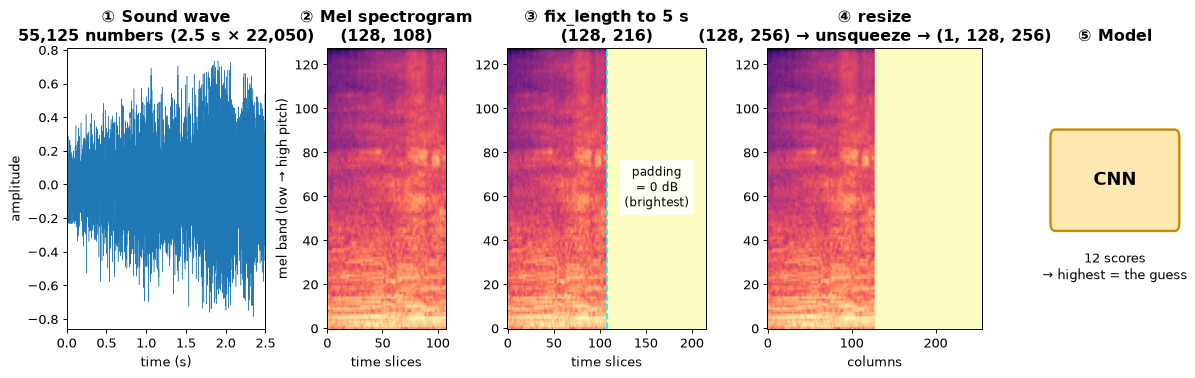

In plain words:

1. 🔊 A clip of Quran recitation is just a long list of numbers (the sound wave).
2. 🖼️ We turn those numbers into a **picture of the sound**, called a **mel spectrogram**.
3. 🧠 A **CNN** (a model that is good at looking at pictures, like in Project 02) looks at that picture.
4. 🏷️ It gives **12 scores**, one for each reciter. The **highest score is the guess**.

That's it. Everything below is just these 4 steps in more detail.

---

## 1. The data: a list of addresses

`files_paths.csv` is like a **phone book**. It does **not** contain any sound. It only says **where** each file is and **who** is reading:

| FilePath | Class |
|---|---|
| `../data/.../Dataset/Dataset/Mohammed_Aluhaidan/lohaidan_171.wav` | Mohammed_Aluhaidan |
| ... **6,687 rows** in total ... | |

- There are **12 reciters**, with **455 to 696 clips** each, so the classes are fairly balanced (see the bar chart above).
- The model only understands numbers, so `LabelEncoder` gives every name a number, in alphabetical order:

| Number | Reciter | Number | Reciter |
|---|---|---|---|
| 0 | AbdulBari_Althubaity | 6 | Mohammed_Aluhaidan |
| 1 | AbdulRahman_Alsudais | 7 | Mohammed_Ayoub |
| 2 | Abdullah_Albuaijan | 8 | Nasser_Alqutami |
| 3 | Ali_Alhothaify | 9 | Saad_Alghamdi |
| 4 | Bander_Balilah | 10 | Saud_Alshuraim |
| 5 | Maher_Almuaiqly | 11 | Yasser_Aldossary |

Then the table is shuffled and cut into 3 groups. Every clip lands in **exactly one** group:

| Group | Clips | Its job | Like... |
|---|---|---|---|
| `train` | 4,681 (70%) | the model **learns** from these | 📘 the practice book |
| `val` | 1,003 (15%) | checked after every epoch, **no learning** | 📝 a weekly quiz |
| `test` | 1,003 (15%) | checked once at the very end, **no learning** | 🎓 the final exam |

---

## 2. One clip becomes one picture: `get_spectrogram()`

| Line | What it does, in plain words | Shape |
|---|---|---|
| `librosa.load(...)` | Read the file as **22,050 numbers per second**. A 2.5 s clip becomes **55,125 numbers** | `(55125,)` |
| `melspectrogram(...)` | Cut the sound into many tiny time slices and check **which pitches are in each slice**. 128 rows of pitch, 108 time slices | `(128, 108)` |
| `power_to_db(...)` | Change "how strong" into **decibels** (a loudness scale like our ears). Loudest = **0**, quietest = **−80** | `(128, 108)` |
| `fix_length(...)` | Make every clip **5 seconds long** by filling the empty part | `(128, 216)` |
| `resize(...)` | Stretch to one fixed picture size | `(128, 256)` |

**How to read the picture:** left → right is **time**, bottom → top is **pitch** (low → high), bright = **loud**.

Here is one clip from 6 different "voices":

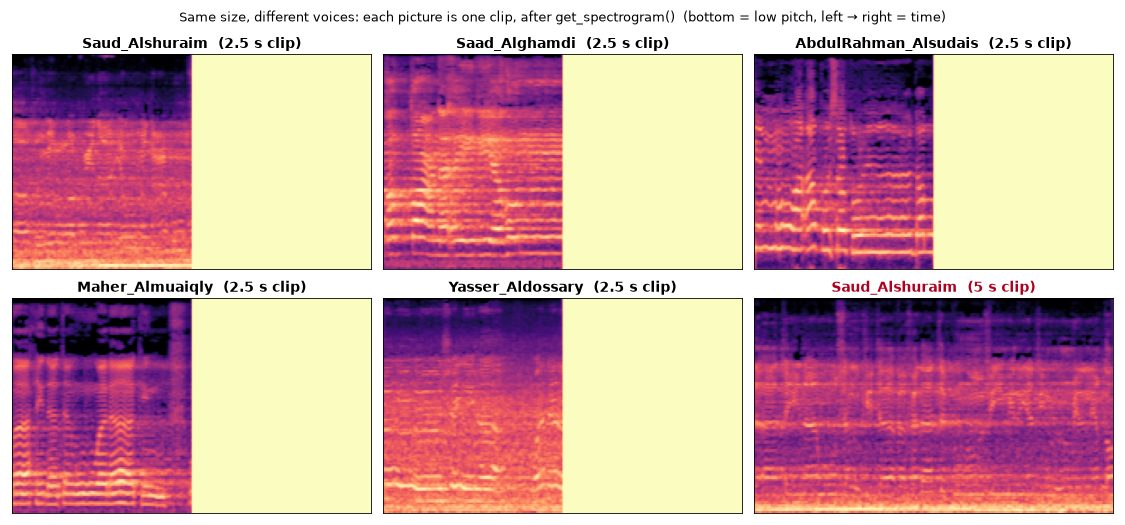

- Every reciter leaves a slightly different pattern of lines and brightness. That pattern is the **"voice fingerprint"** the model has to learn.
- ⚠️ **Why is the right half a flat yellow block?** Most clips are only **2.5 s** long. `fix_length` fills the missing 2.5 s with the number **0**, and in decibels **0 means "the loudest"**, so it shows up as a bright block. A 5-second clip (bottom right) has no block.

---

## 3. The Dataset: cook everything first, then just serve

`CustomAudioDataset` works like **meal prep** 🍱:

| Function | When it runs | What it does | Like... |
|---|---|---|---|
| `__init__` | **once**, when you write `CustomAudioDataset(train)` | makes the picture for **every** clip and keeps them all in a list (`self.audios`). This is slow: **about 5 minutes** for all 6,687 clips | cooking all the meals on Sunday |
| `__len__` | when someone asks "how many?" | returns 4,681 for `train` | counting the boxes |
| `__getitem__` | **every time** one item is needed | takes one ready picture, adds the "1 sheet" dimension, sends it to the GPU, and returns `(picture, label)` | grabbing one box from the fridge |

- **Why cook first?** Making a spectrogram takes time. If we made it again in every epoch, training would be much slower. So the heavy work happens **once**.
- **Who calls `__getitem__`?** You can call it yourself with `train_dataset[0]`. During training, the **DataLoader** calls it for you, thousands of times.
- **Why does `self.audios` stay on the CPU?** Think of the RAM (16 GB) as a **big storage room** and the GPU (6 GB) as a **small desk**. All the pictures stay in the storage room. Only the 16 we are working on go to the desk.

---

## 4. The DataLoader: 16 pictures per tray

The DataLoader picks **16 clips at random**, asks the Dataset for each one, and **stacks** them into one block of numbers:

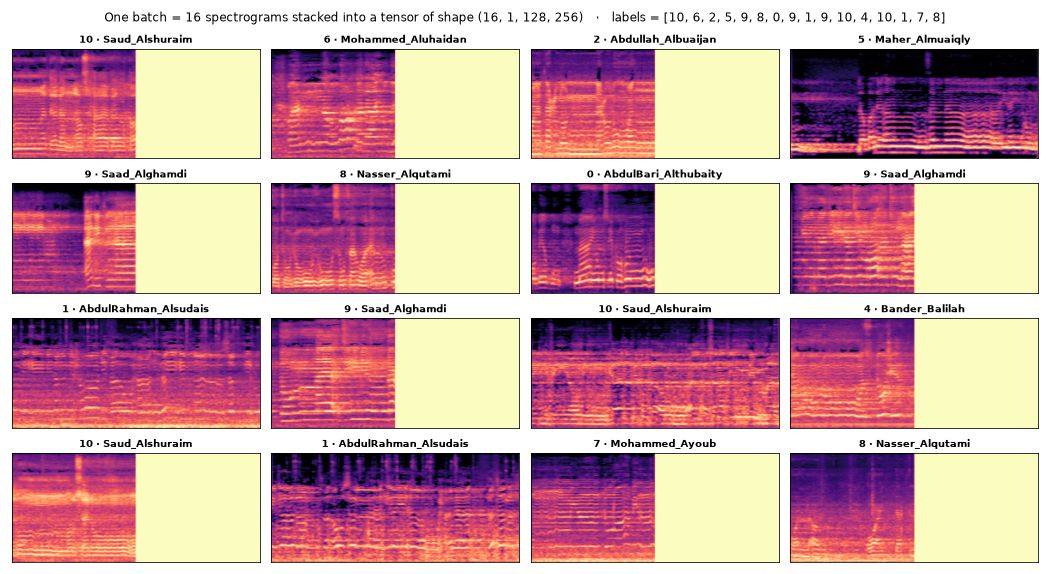

```
pictures: shape (16, 1, 128, 256)   → 16 clips × 1 sheet × 128 pitch rows × 256 time columns
labels:   shape (16,)               → 16 reciter numbers, for example [10, 6, 2, 5, ...]
```

- One "tray" is called a **batch**. `train_loader` has **293 batches** (292 full trays of 16, plus one last tray of 9).
- **Why "1 sheet"?** A colour photo in Project 02 has 3 sheets (Red, Green, Blue). A spectrogram has only one number per spot (how loud it is), so it has **1 sheet**.

---

## 5. 🧠 The model, step by step

### 5.1 The idea in one sentence

> The model looks at the picture **through a tiny window** to find small patterns, **shrinks** the picture, does that **3 times**, and then a **panel of judges** turns everything into **12 scores**.

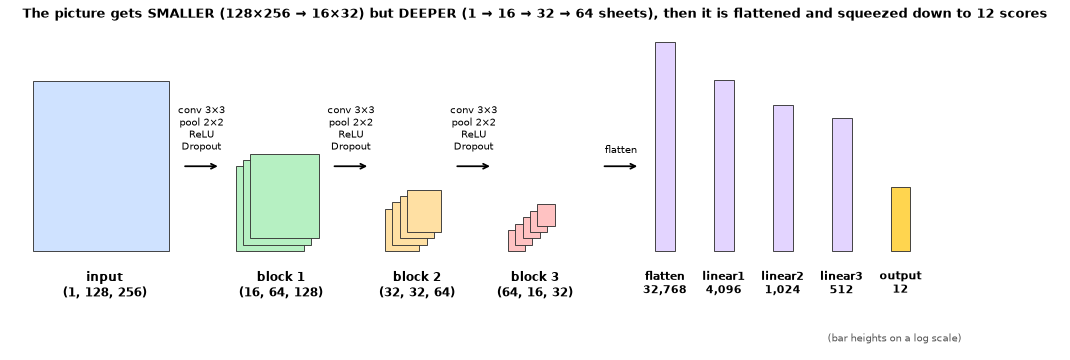

The same thing as a table, for **one batch of 16 clips**:

| Step | Shape after this step | What changed, in plain words |
|---|---|---|
| input | `(16, 1, 128, 256)` | 16 pictures, 1 sheet each |
| `conv1` | `(16, 16, 128, 256)` | **16 pattern finders** → 16 new sheets per picture |
| `pooling` + `relu` + `dropout` | `(16, 16, 64, 128)` | each sheet is **half as tall and half as wide** |
| `conv2` | `(16, 32, 64, 128)` | **32 pattern finders** → 32 sheets |
| `pooling` + `relu` + `dropout` | `(16, 32, 32, 64)` | half again |
| `conv3` | `(16, 64, 32, 64)` | **64 pattern finders** → 64 sheets |
| `pooling` + `relu` + `dropout` | `(16, 64, 16, 32)` | half again |
| `flatten` | `(16, 32768)` | all sheets laid out in **one long line**: 64 × 16 × 32 = 32,768 |
| `linear1` + `dropout` | `(16, 4096)` | 4,096 numbers |
| `linear2` + `dropout` | `(16, 1024)` | 1,024 numbers |
| `linear3` + `dropout` | `(16, 512)` | 512 numbers |
| `output` | `(16, 12)` | **12 scores per clip**, one for each reciter |

The first number, **16**, never changes. It's just "16 clips in this batch". Now let's open each step.

---

### 5.2 Step 1: `Conv2d`, the pattern finder 🔍

A **filter** is a tiny **3 × 3 window** with 9 numbers inside. It **slides** over the picture, one spot at a time. At every spot it does **multiply and add**, then writes down **one number**:

- big number = "**I found my pattern here!**" (bright)
- small number = "nothing here" (dark)

**A tiny example.** Filter A looks for a **horizontal line**:

```
filter A          a spot WITH a line         a flat spot (no line)
-1 -1 -1          1  1  1                    3  3  3
 2  2  2          5  5  5                    3  3  3
-1 -1 -1          1  1  1                    3  3  3

multiply each number with the number at the same place, then add everything:
WITH a line:   (-1-1-1)×1 + (2+2+2)×5 + (-1-1-1)×1  = -3 + 30 - 3 = 24   → big → "found it!" ✅
flat spot:     (-1-1-1)×3 + (2+2+2)×3 + (-1-1-1)×3  = -9 + 18 - 9 =  0   → "nothing here"
```

Here are two hand-made filters sliding over a real spectrogram (white = pattern found):

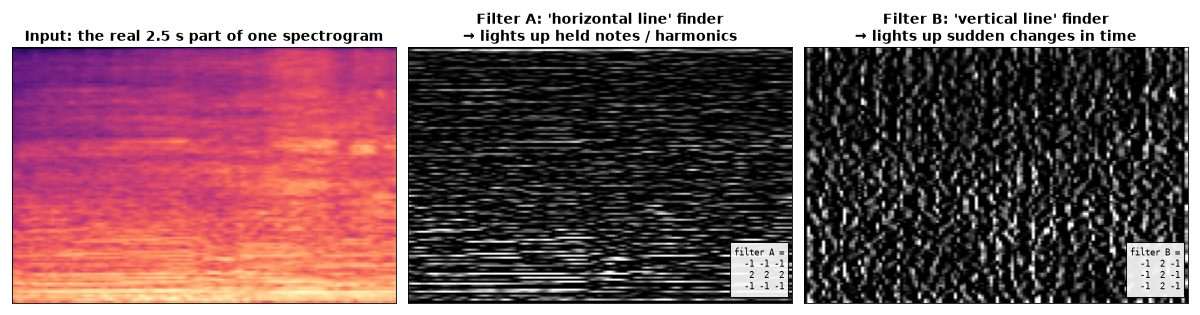

- Filter A lights up **long horizontal lines**: a held note and its harmonics (the "colour" of a voice).
- Filter B lights up **short vertical lines**: places where the sound suddenly changes (a new letter starts).
- ⭐ **My model does NOT use hand-made filters.** It starts with **random** numbers in every filter and **learns by itself** which patterns help to tell the reciters apart.

Reading `nn.Conv2d(1, 16, kernel_size=3, padding=1)`:

| Part | Meaning |
|---|---|
| `1` | it reads **1 sheet** (the spectrogram) |
| `16` | it has **16 different filters**, so it makes **16 new sheets**. Each sheet answers "where is *my* pattern?" |
| `kernel_size=3` | every filter is **3 × 3** |
| `padding=1` | add a **1-pixel frame of zeros** around the picture, so the size stays 128 × 256 |

`conv2` reads those 16 sheets with 32 filters, and `conv3` reads 32 sheets with 64 filters. Later filters combine small patterns into **bigger, more voice-specific patterns**.

---

### 5.3 Step 2: `MaxPool2d(2, 2)`, shrink and keep the strongest 🗜️

Cut every sheet into **2 × 2 squares** and keep **only the biggest number** of each square:

```
[1 3 | 2 0]
[5 2 | 1 4]          [5 4]
-----------    →     [1 8]
[0 1 | 7 2]
[1 0 | 3 8]
```

- The sheet becomes **half as tall and half as wide** (128 × 256 → 64 × 128).
- It keeps the answer "**was the pattern found somewhere in this area?**" and forgets the exact spot.
- It has **nothing to learn** (0 parameters). It's a fixed rule.

---

### 5.4 Step 3: `ReLU`, throw away the negatives ✂️

```
[-0.7, 0.3, -0.1, 1.2]   →   [0, 0.3, 0, 1.2]
```

Every negative number becomes **0**, and positive numbers stay the same. It sounds too simple to matter, but it's the "**bender**" that lets the model learn **curved, complicated** rules instead of only straight-line rules. In my untrained model, **55%** of the numbers after `conv1` are negative, so ReLU really changes a lot.

---

### 5.5 Step 4: `Dropout(0.5)`, random days off 🎲 (new in this project!)

During training, Dropout **switches off about half of the numbers at random**, and a **different half every batch**:

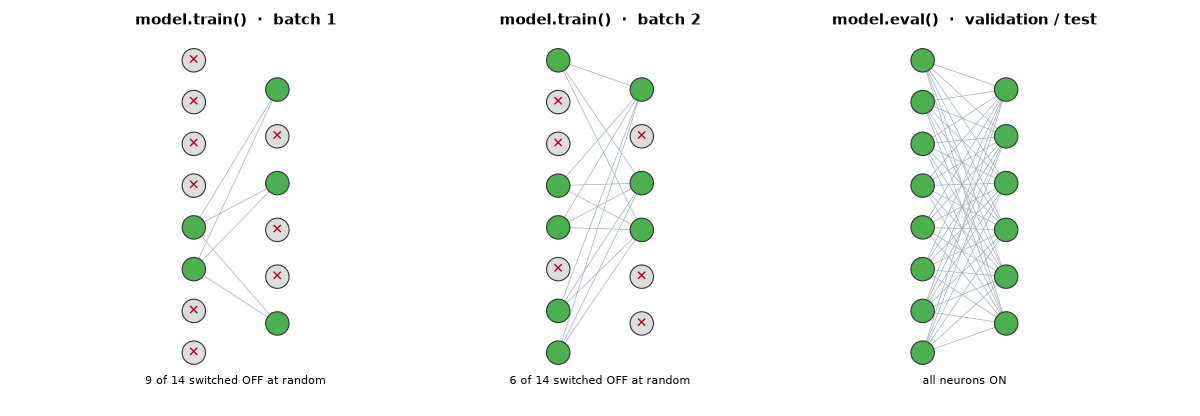

> 🏫 **Analogy:** a study group where, every day, half of the members are randomly told to stay home. Nobody can rely on one "smart friend", so **everyone has to understand the material**. In the same way, the model can't **memorise** the training clips using a few special numbers. It has to learn patterns that really work.

- The numbers that stay ON are **doubled**, so the total stays about the same. Example: `[1, 1, 1, 1, 1, 1, 1, 1]` → `[0, 0, 2, 2, 2, 0, 0, 0]`.
- During the quiz and the exam, **everyone must be present**. That's why the training cell now has:
  - `model.train()` → Dropout **ON** (learning)
  - `model.eval()` → Dropout **OFF** (validation and test)

**Proof with real numbers.** I gave the **same clip** to my untrained model 3 times in each mode:

| Mode | Run 1 | Run 2 | Run 3 |
|---|---|---|---|
| `model.train()` (Dropout ON) | reciter 10, 99.0% sure | reciter 2, 51.6% sure | reciter 5, 71.5% sure |
| `model.eval()` (Dropout OFF) | reciter 8, 10.9% sure | reciter 8, 10.9% sure | reciter 8, 10.9% sure |

With Dropout ON, the same clip gets **a different answer every time**. That's fine while learning, but terrible for a quiz. The video didn't switch Dropout off, so its validation and test scores would come out noisier and lower than they really are.

---

### 5.6 Repeat 3 times: the picture gets smaller but "deeper"

One clip, followed through the 3 blocks (each block = conv → pool → ReLU → Dropout):

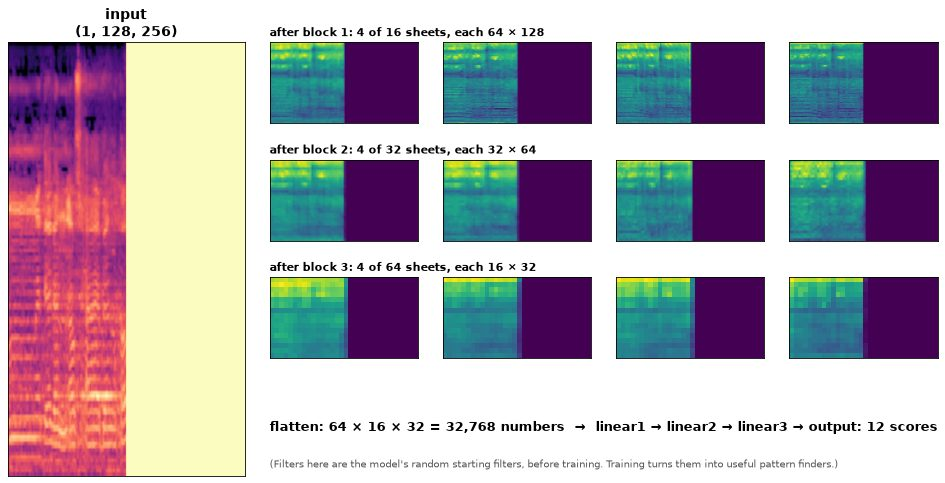

```
size of each sheet:   128 × 256  →  64 × 128  →  32 × 64  →  16 × 32     (smaller)
number of sheets:          1     →     16     →     32    →     64       (deeper)
```

Small sheets but many of them: each sheet now means something like "**this kind of voice pattern is here, roughly in this area**".

---

### 5.7 Step 5: `flatten`, put everything in one line 📏

The judges (next step) can only read **one long line** of numbers, not a stack of sheets. So all 64 sheets of 16 × 32 are laid out one after another:

```
64 sheets × 16 × 32 = 32,768 numbers in one line
```

(In `forward`, `x.view(x.size(0), -1)` already does this, so the `self.flatten(x)` line right after it has nothing left to do. It's harmless. It just comes from the video.)

---

### 5.8 Step 6: the `Linear` layers, a panel of judges ⚖️

`nn.Linear(32768, 4096)` means: **4,096 judges**, and **each judge looks at all 32,768 numbers**, gives each number its own importance (a **weight**), adds everything up, and writes **one score**. This is the same "multiply and add" neuron as in Project 01, just many more of them.

```
32,768  →  linear1  →  4,096  →  linear2  →  1,024  →  linear3  →  512  →  output  →  12
```

Each layer has fewer judges, so the information is **squeezed** step by step until only **12 scores** are left.

**Parameters** = all the numbers the model can learn (the filters' numbers, the judges' weights, and a starting value called **bias**). Here is where they live:

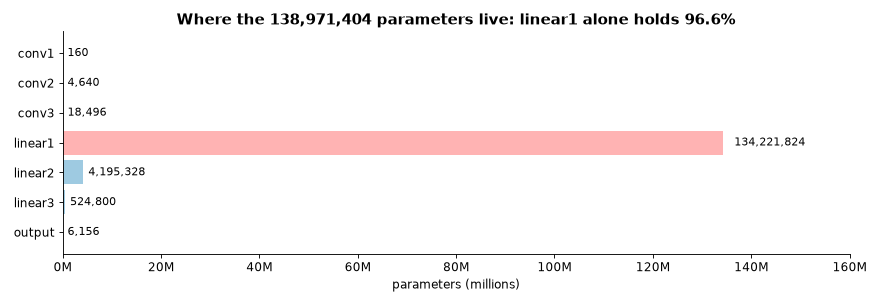

- `linear1` alone has 32,768 × 4,096 weights + 4,096 biases = **134,221,824** numbers, which is **96.6%** of the whole model.
- The 3 conv layers together have only **23,296**, because the same small filter is **reused at every spot** of the picture.
- In total: **138,971,404** parameters. For comparison: Project 01 had 121, Project 02 had 4.3 million, Project 03 had 5.6 million, and the BERT model in Project 05 has about 110 million. 😮

---

### 5.9 Step 7: 12 scores → a guess 🏷️

The model gives **12 raw scores**. To read them as percentages, we turn them into numbers that add up to 100% (this is called **softmax**). The **highest one is the guess** (`torch.argmax`).

The first clip of the batch above is **Saud_Alshuraim (10)**. Before any training, the model said:

```
reciter:    0     1     2     3     4     5     6     7     8     9     10    11
percent:   9.5   6.4   9.5   7.4   8.0   6.6   8.6   6.8  10.9   8.2  10.9   7.2
guess: 8 (Nasser_Alqutami)  ❌   (the right answer was 10)
```

Every reciter gets **about 8%** (100% ÷ 12 = 8.3%). The model **doesn't know anything yet**, it's basically guessing. Training is what makes one bar stand out.

---

## 6. Loss and optimizer (same as Project 02)

| Line | Plain words |
|---|---|
| `criterion = nn.CrossEntropyLoss()` | Measures **how wrong** a guess is. Small when the right reciter gets a high percentage, big when it gets a low one. For the untrained batch above it was **2.57**, close to **2.48**, the "pure guessing between 12" level |
| `optimizer = Adam(model.parameters(), lr=LR)` | The **mechanic** who adjusts all 139 million numbers a tiny bit after every batch. `lr = 0.0001` is the **size of each adjustment** |

---

## 7. What happens in the training cell

For **every batch** of 16 clips, 4 small steps happen:

```
① GUESS            outputs = model(inputs)             → 12 scores for each of the 16 clips
② MEASURE          train_loss = criterion(...)         → one "how wrong" number
③ FIND DIRECTION   train_loss.backward()               → for each of the 139 million numbers: "should it go up or down?"
④ FIX              optimizer.step()                    → move every number a tiny bit in the right direction
                   optimizer.zero_grad()               → clear the notes before the next batch
```

- **1 epoch** = all **293** batches once. **25 epochs** = 293 × 25 = **7,325** small fixes.
- After each epoch, the model takes the **quiz** (`val_loader`) in `model.eval()` mode and inside `torch.no_grad()` (= "don't take any learning notes, just answer").
- Loss is divided by `len(train_loader)` and `len(val_loader)`, so it's the **average loss per batch** and the two can be compared fairly.
- Each epoch also prints **how many seconds it took**.

### What my training run looked like (the output right below)

| Epochs | Validation accuracy | What was happening |
|---|---|---|
| 1 | **10.2%** | still guessing: 100% ÷ 12 ≈ 8.3% is exactly "random" |
| 2 → 4 | 17.7% → **52.7%** | it starts to "hear" the differences |
| 5 → 11 | 55.7% → **87.6%** | it learns fast |
| 12 → 19 | 85.7% → **94.1%** | slower and a bit bumpy, which is normal with Dropout |
| 20 → 25 | 95.2% → **97.0%** | polishing. Final train accuracy: **93.3%** |

- Each epoch took about **25–29 seconds**, so the whole training took about **11 minutes**.
- **Final exam:** on the test set (1,003 clips the model never trained on) the model scored **96.7%**, only **33 wrong** (see *Testing* and *Inference* below).
- 🤔 **Why is validation accuracy higher than training accuracy almost the whole time?** Because during training, Dropout switches off half of the model, which makes the work harder (like studying with half of your notes hidden). During validation, `model.eval()` lets the full model answer.
- 🎲 **Training starts from random numbers, so every run is different.** An earlier run of exactly the same code was slower to start (stuck at about 8% for 4 epochs) and ended at **86.1%**. Same code, different starting numbers, different result.

---

## 8. Project 02 vs Project 04

| | Project 02 (animal faces) | Project 04 (Quran reciters) |
|---|---|---|
| Raw data | photos (JPG) | sound (WAV) |
| Picture | the photo itself | a **mel spectrogram** made from the sound |
| Sheets per picture | 3 (Red, Green, Blue) | **1** |
| Input shape | (3, 128, 128) | **(1, 128, 256)** |
| When pictures are made | one by one, when asked (`__getitem__`) | **all at once, at the start** (`__init__`) |
| Classes | 3 | **12** |
| New layer | ReLU | **Dropout** (so `train()` / `eval()` matter) |
| Parameters | 4,288,067 | **138,971,404** |
| New libraries | torchvision | **librosa**, scikit-image |

---

## 9. Mini dictionary

| Word | Simple meaning |
|---|---|
| **Spectrogram** | A picture of sound: time left → right, pitch bottom → top, bright = loud |
| **Mel** | A pitch scale that matches how our ears hear |
| **Decibel (dB)** | A loudness scale. Here, 0 = loudest and −80 = quietest |
| **Batch** | A tray of 16 clips processed together |
| **Sheet / channel** | One 2D grid of numbers. The input has 1, and after `conv1` there are 16 |
| **Filter** | A tiny 3 × 3 window of numbers that looks for one pattern |
| **Convolution (`Conv2d`)** | Sliding filters over the picture and doing multiply-and-add at every spot |
| **Max pooling** | Keep the biggest number in every 2 × 2 square, so the sheet becomes half the size |
| **ReLU** | Negative numbers become 0, so the model can learn curved rules |
| **Dropout** | Randomly switch off half of the numbers while learning, so the model can't memorise |
| **`model.train()` / `model.eval()`** | Learning mode (Dropout ON) / quiz-and-exam mode (Dropout OFF) |
| **Flatten** | Lay out all the sheets in one long line |
| **Linear layer** | A panel of "judges": every judge looks at every number and gives one score |
| **Parameter** | A number the model can learn (filter numbers, weights, biases) |
| **Softmax** | Turns 12 scores into 12 percentages that add up to 100% |
| **argmax** | "Which position has the highest number?" = the guess |
| **Epoch** | Going through all the training batches once |

---

## ✨ Worth knowing (feel free to skip)

- **The bright block might be a shortcut.** Only some reciters have 5-second clips (and therefore pictures *without* the block), so the model may partly learn "block or no block" instead of only the voice. I'm keeping the video's approach for now.
- **No ReLU between the Linear layers** (same as the video). That means `linear1` → `linear2` → `linear3` → `output` behave almost like **one** big Linear layer. Adding a ReLU between them is a common small improvement.
- **The `TqdmWarning` under "Create Dataset Objects" is harmless.** librosa loads a helper library that wants to draw fancy progress bars in notebooks, and it just says it can't. Nothing is wrong.

## References
- Omar M. Atef, [PyTorch Tutorial 4 – Audio Classification](https://www.youtube.com/watch?v=uj6s5uhwDkY) and the original notebook [Ex_4_Audio_Classification.ipynb](https://github.com/omaratef3221/pytorch_tutorials/blob/main/Ex_4_Audio_Classification.ipynb)
- PyTorch docs: [`nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`nn.MaxPool2d`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html), [`nn.Dropout`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html), [`nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), [`Module.train()` / `Module.eval()`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval)
- Srivastava et al., 2014. [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html), the paper behind Dropout

## Training

In [16]:
total_loss_train_plot = [] # Empty list to be filled with train loss after each epoch
total_loss_validation_plot = [] # Empty list to be filled with validation loss after each epoch
total_acc_train_plot = [] # Empty list to be filled with train accuracy after each epoch
total_acc_validation_plot = [] # Empty list to be filled with validation accuracy after each epoch

for epoch in range(EPOCHS):
    start_time = time.time() # We use this to calculate the time of each epoch, it starts a counter once called
    total_acc_train = 0
    total_loss_train = 0
    total_loss_val = 0
    total_acc_val = 0

    model.train() # Training mode: Dropout is ON (randomly switches off half of the neurons)
    for inputs, labels in train_loader:
        outputs = model(inputs)
        train_loss = criterion(outputs, labels)
        total_loss_train += train_loss.item()
        train_loss.backward()

        train_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
        total_acc_train += train_acc
        optimizer.step()
        optimizer.zero_grad()

    model.eval() # Evaluation mode: Dropout is OFF (every neuron is used)
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            val_loss = criterion(outputs, labels)
            total_loss_val += val_loss.item()

            val_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
            total_acc_val += val_acc

    total_loss_train_plot.append(round(total_loss_train/len(train_loader), 4))
    total_loss_validation_plot.append(round(total_loss_val/len(val_loader), 4))
    total_acc_train_plot.append(round(total_acc_train/(train_dataset.__len__())*100, 4))
    total_acc_validation_plot.append(round(total_acc_val/(val_dataset.__len__())*100, 4))

    print(f"Epoch {epoch+1}/{EPOCHS} ({time.time() - start_time:.1f} s), Train Loss: {total_loss_train_plot[-1]}, Train Accuracy: {total_acc_train_plot[-1]}")
    print(f"              Validation Loss: {total_loss_validation_plot[-1]}, Validation Accuracy: {total_acc_validation_plot[-1]}")
    print("=" * 30)

Epoch 1/25 (28.7 s), Train Loss: 7.593, Train Accuracy: 10.2115
              Validation Loss: 2.4824, Validation Accuracy: 10.1695


Epoch 2/25 (25.4 s), Train Loss: 2.4356, Train Accuracy: 12.3478
              Validation Loss: 2.4697, Validation Accuracy: 17.7468


Epoch 3/25 (25.6 s), Train Loss: 2.3302, Train Accuracy: 17.1117
              Validation Loss: 2.2251, Validation Accuracy: 33.3001


Epoch 4/25 (25.8 s), Train Loss: 2.0457, Train Accuracy: 28.605
              Validation Loss: 1.7558, Validation Accuracy: 52.7418


Epoch 5/25 (25.1 s), Train Loss: 1.8037, Train Accuracy: 37.6415
              Validation Loss: 1.5597, Validation Accuracy: 55.7328


...

Epoch 21/25 (25.7 s), Train Loss: 0.2569, Train Accuracy: 91.9675
              Validation Loss: 0.1898, Validation Accuracy: 95.4138


Epoch 22/25 (25.6 s), Train Loss: 0.247, Train Accuracy: 92.9075
              Validation Loss: 0.1908, Validation Accuracy: 95.2144


Epoch 23/25 (25.8 s), Train Loss: 0.2205, Train Accuracy: 93.0784
              Validation Loss: 0.2031, Validation Accuracy: 95.6132


Epoch 24/25 (25.6 s), Train Loss: 0.2184, Train Accuracy: 93.8047
              Validation Loss: 0.1275, Validation Accuracy: 97.2084


Epoch 25/25 (26.1 s), Train Loss: 0.2108, Train Accuracy: 93.3348
              Validation Loss: 0.129, Validation Accuracy: 97.009


## Testing

In [17]:
model.eval() # Evaluation mode: Dropout is OFF (every neuron is used)
with torch.no_grad():
    total_acc_test = 0
    total_loss_test = 0

    for inputs, labels in test_loader:
        outputs = model(inputs)
        test_loss = criterion(outputs, labels)
        total_loss_test += test_loss.item()

        test_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
        total_acc_test += test_acc

    print(f"Test Loss: {round(total_loss_test/len(test_loader), 4)}, Test Accuracy: {round(total_acc_test/(test_dataset.__len__())*100, 4)}")

Test Loss: 0.1409, Test Accuracy: 96.7099


## Plotting Training Progress

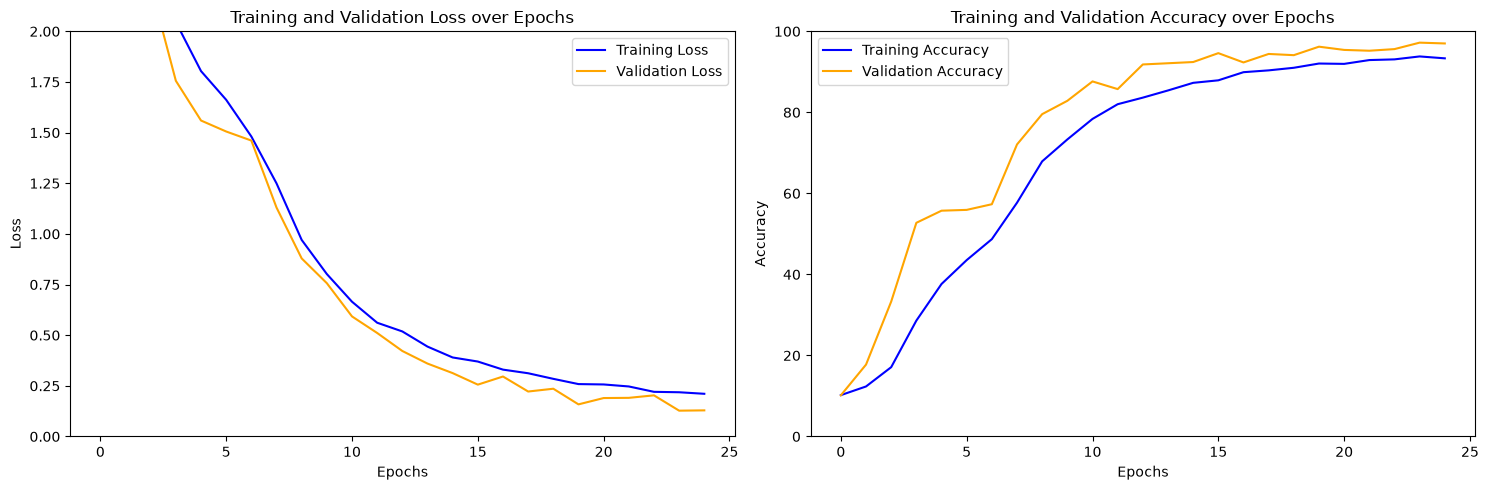

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label="Training Loss", color="blue")
axs[0].plot(total_loss_validation_plot, label="Validation Loss", color="orange")
axs[0].set_title("Training and Validation Loss over Epochs")
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Loss")
axs[0].set_ylim([0, 2])
axs[0].legend()

axs[1].plot(total_acc_train_plot, label="Training Accuracy", color="blue")
axs[1].plot(total_acc_validation_plot, label="Validation Accuracy", color="orange")
axs[1].set_title("Training and Validation Accuracy over Epochs")
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy")
axs[1].set_ylim([0, 100])
axs[1].legend()

plt.tight_layout()

plt.show()

## Inference

Now let's use the trained model like in real life: give it **one audio file** and ask *"who is reading?"*

1. Turn the file into a spectrogram with the **same** `get_spectrogram()` used for training.
2. Reshape it to `(1, 1, 128, 256)`: 1 clip, 1 sheet.
3. Switch the model to `eval()` mode, get 12 scores, and turn them into percentages with `softmax`.
4. The highest percentage is the guess. `label_encoder` turns its number back into a name.

*The inference and visualization cells below were added with help from Claude (AI).*

In [19]:
def predict_audio(file_path):
    spectrogram = train_dataset.get_spectrogram(file_path) # Same preprocessing as in training: load → mel spectrogram → dB → fix_length → resize
    audio = torch.tensor(spectrogram, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device) # (128, 256) → (1, 1, 128, 256): 1 clip with 1 sheet

    model.eval() # Evaluation mode: Dropout is OFF
    with torch.no_grad():
        probabilities = torch.softmax(model(audio), dim=1)[0].cpu().numpy() # 12 scores → 12 percentages that add up to 1

    predicted_name = label_encoder.inverse_transform([probabilities.argmax()])[0] # The highest percentage is the guess, turned back into a name
    return predicted_name, probabilities, spectrogram

File:      lohaidan_159.wav
True:      Mohammed_Aluhaidan
Predicted: Mohammed_Aluhaidan (99.2% sure)


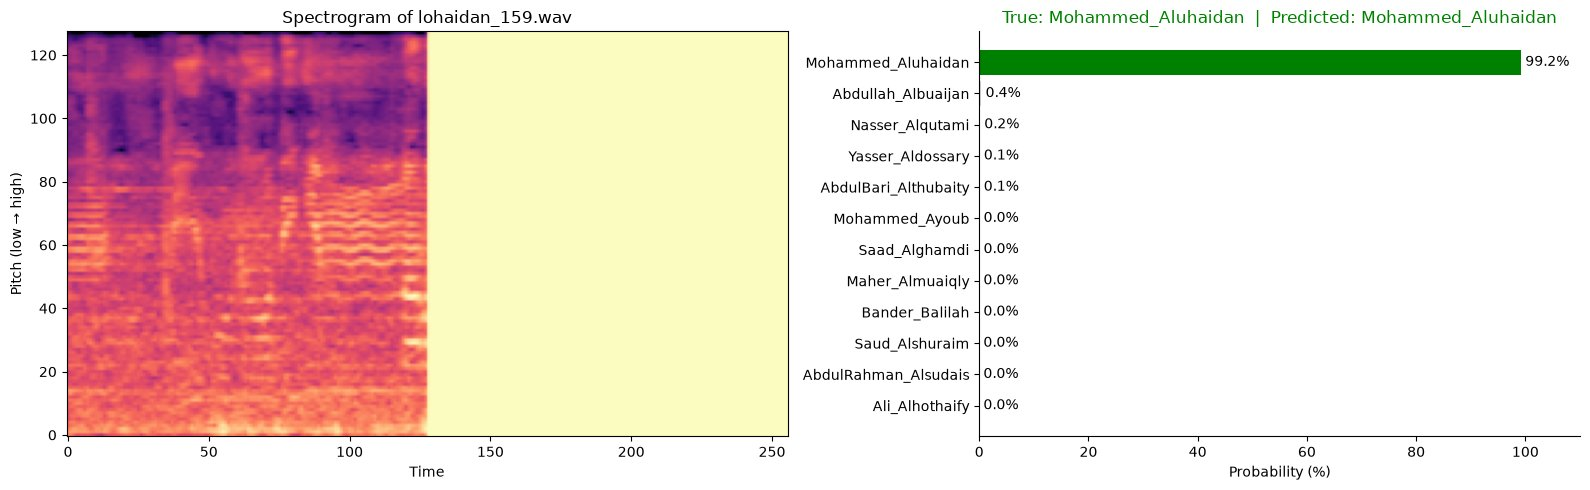

In [20]:
audio_to_predict = test.iloc[0] # The first clip of the test split, so the model never trained on it
true_name = label_encoder.inverse_transform([audio_to_predict["Class"]])[0]
predicted_name, probabilities, spectrogram = predict_audio(audio_to_predict["FilePath"])

print("File:     ", audio_to_predict["FilePath"].split("/")[-1])
print("True:     ", true_name)
print("Predicted:", predicted_name, f"({probabilities.max() * 100:.1f}% sure)")

fig, axs = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1]})

axs[0].imshow(spectrogram, origin="lower", aspect="auto", cmap="magma") # The "picture of the sound" the model looked at
axs[0].set_title(f"Spectrogram of {audio_to_predict['FilePath'].split('/')[-1]}")
axs[0].set_xlabel("Time")
axs[0].set_ylabel("Pitch (low → high)")

order = probabilities.argsort() # Sort the reciters so the most likely one is at the top
names = label_encoder.classes_[order]
colors = ["green" if name == predicted_name == true_name else "red" if name == predicted_name else "steelblue" if name == true_name else "lightgray" for name in names]
bars = axs[1].barh(names, probabilities[order] * 100, color=colors)
axs[1].bar_label(bars, fmt="%.1f%%", padding=3)
axs[1].set_xlim(0, 110)
axs[1].set_xlabel("Probability (%)")
axs[1].set_title(f"True: {true_name}  |  Predicted: {predicted_name}", color="green" if predicted_name == true_name else "red")
axs[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Predictions on Unseen Test Clips

12 random clips from the **test set** (the model never trained on them). A **green** title means the guess is correct, a **red** title means it's wrong.

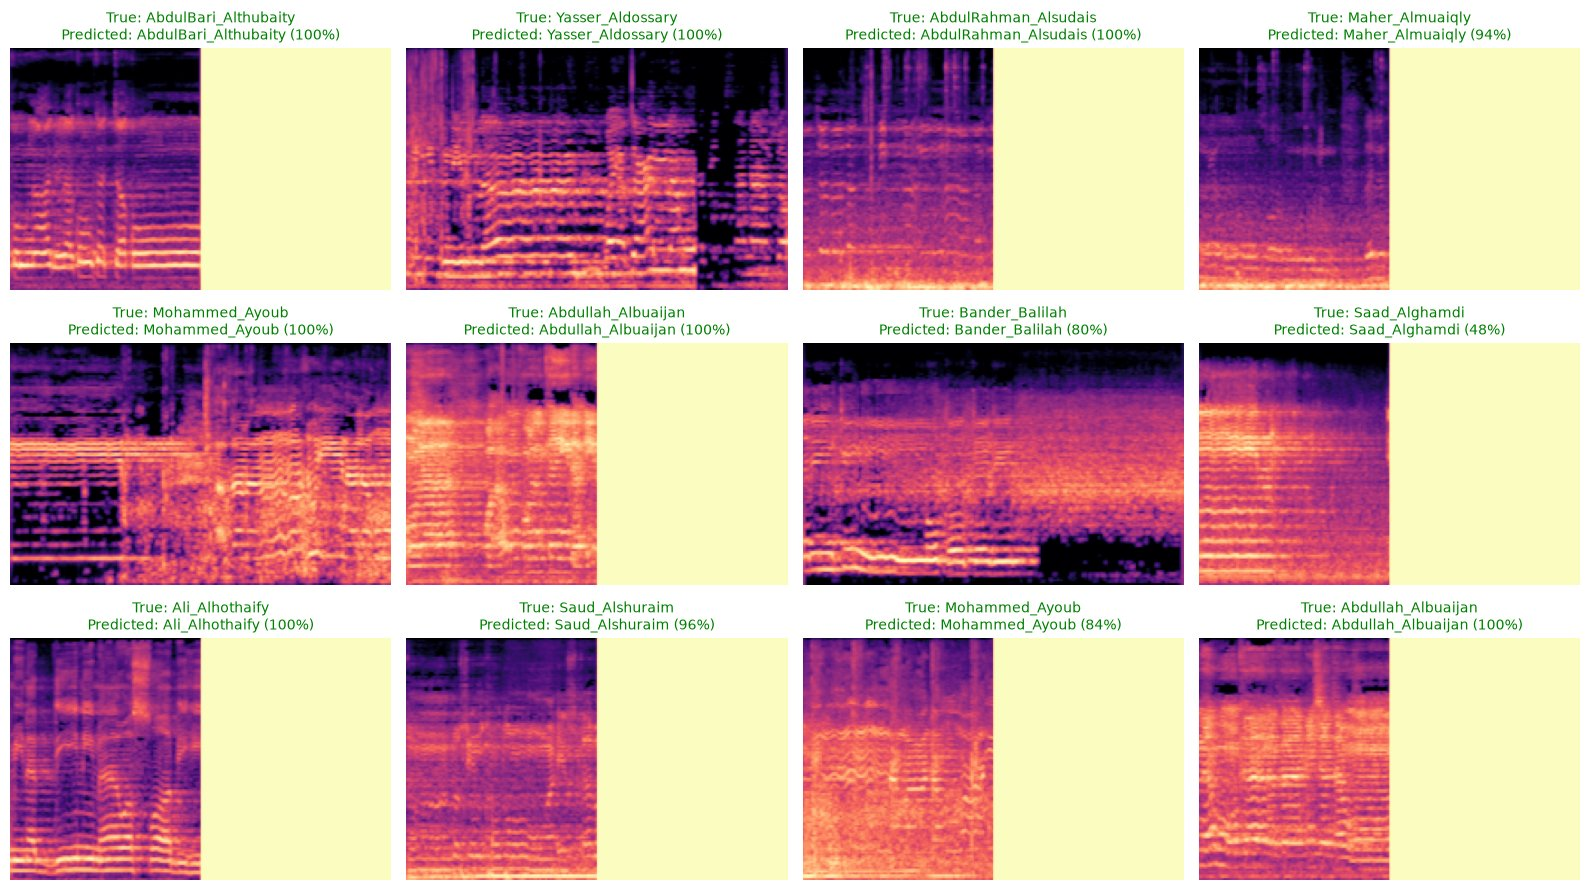

In [21]:
n_rows = 3
n_cols = 4
sample = test.sample(n_rows * n_cols, random_state=7) # 12 random rows from the test table

f, axarr = plt.subplots(n_rows, n_cols, figsize=(16, 9))
for ax, (path, true_label) in zip(axarr.flat, sample.itertuples(index=False)):
    true_name = label_encoder.inverse_transform([true_label])[0]
    predicted_name, probabilities, spectrogram = predict_audio(path) # Same function as in the cell above
    ax.imshow(spectrogram, origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"True: {true_name}\nPredicted: {predicted_name} ({probabilities.max() * 100:.0f}%)",
                 color="green" if predicted_name == true_name else "red", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Where the Model Gets It Wrong

The whole test set (1,003 clips) in one picture, called a **confusion matrix**:

- Each **row** is the **real** reciter, and each **column** is the model's **guess**.
- The **diagonal** (top-left to bottom-right) counts the **correct** guesses. Everything outside the diagonal is a mistake, and it shows **who was confused with whom**.
- On the right: the test accuracy for each reciter separately.

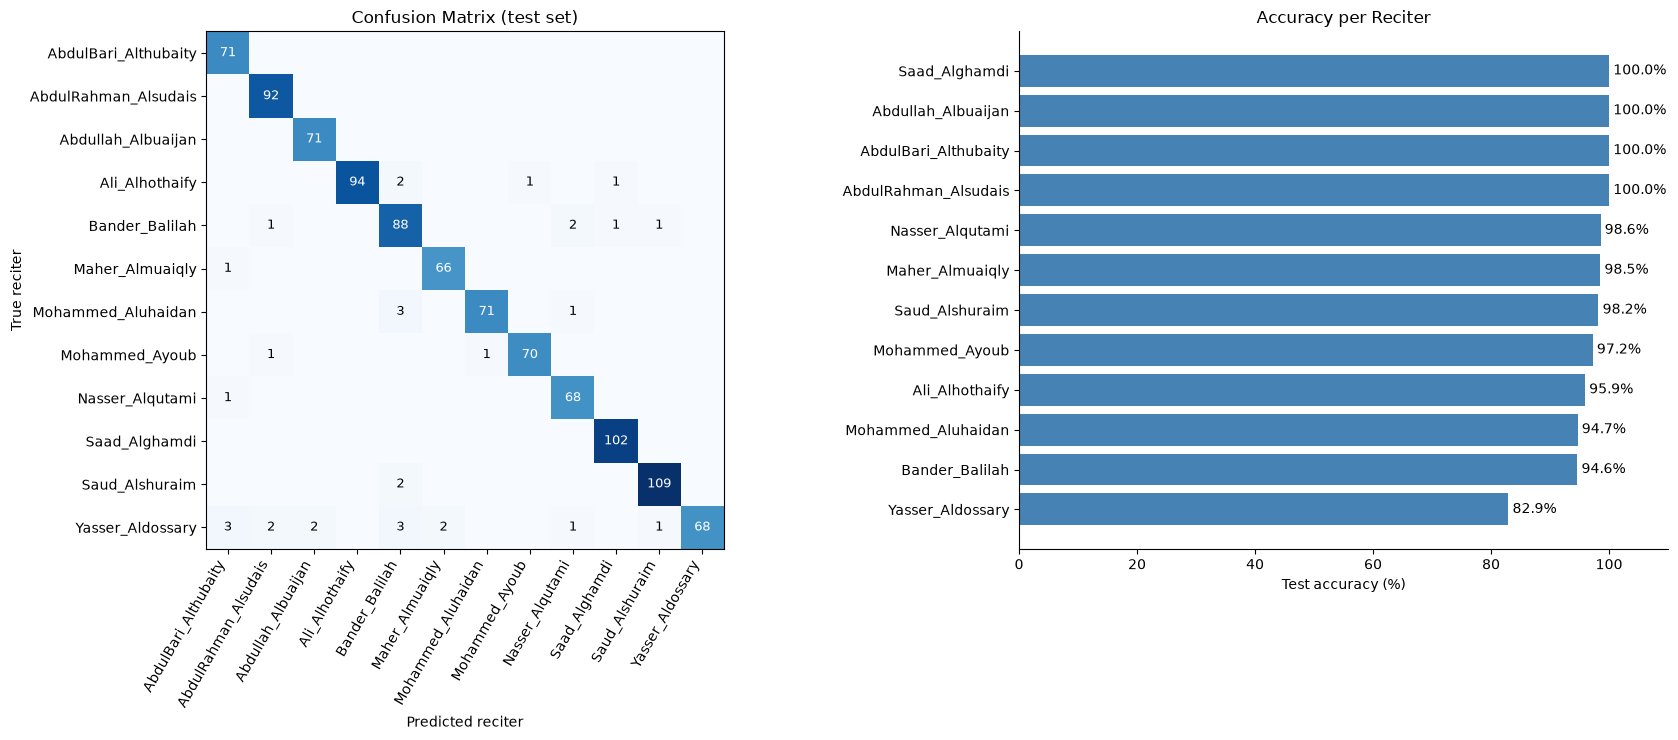

Wrong guesses: 33 out of 1003 test clips


In [22]:
from sklearn.metrics import confusion_matrix

all_predictions = []
all_labels = []
model.eval() # Evaluation mode: Dropout is OFF
with torch.no_grad():
    for inputs, labels in test_loader: # test_loader is not shuffled, so the order follows the test table
        all_predictions += torch.argmax(model(inputs), axis = 1).cpu().tolist()
        all_labels += labels.cpu().tolist()

matrix = confusion_matrix(all_labels, all_predictions)
per_reciter_accuracy = matrix.diagonal() / matrix.sum(axis=1) * 100
names = label_encoder.classes_

fig, axs = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.35, 1]})

axs[0].imshow(matrix, cmap="Blues")
for i in range(len(names)):
    for j in range(len(names)):
        if matrix[i, j] > 0:
            axs[0].text(j, i, matrix[i, j], ha="center", va="center", fontsize=9, color="white" if matrix[i, j] > matrix.max() / 2 else "black")
axs[0].set_xticks(range(len(names)), names, rotation=60, ha="right")
axs[0].set_yticks(range(len(names)), names)
axs[0].set_xlabel("Predicted reciter")
axs[0].set_ylabel("True reciter")
axs[0].set_title("Confusion Matrix (test set)")

order = per_reciter_accuracy.argsort()
bars = axs[1].barh(names[order], per_reciter_accuracy[order], color="steelblue")
axs[1].bar_label(bars, fmt="%.1f%%", padding=3)
axs[1].set_xlim(0, 110)
axs[1].set_xlabel("Test accuracy (%)")
axs[1].set_title("Accuracy per Reciter")
axs[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Wrong guesses: {(matrix.sum() - matrix.trace())} out of {matrix.sum()} test clips")